In [1]:
import physics_tools.coordinates as coords
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from uncertainties import ufloat, umath
from pathlib import Path

def conv_angles(x, y, right=False):
    return coords.double_pendulum_angles(*coords.double_pendulum_conv(x, y), right=right)

In [2]:
DATA_DIR = "initial_positions.csv"
PLOT_DIR_FINAL = "final_plots"

In [3]:
g = 9.81
L_1 = 0.20    # m, Aufhängung -> Mittelgelenk
L_2 = 0.15    # m, Mittelgelenk -> Mitte der Zusatzmasse

# Massen laut Lab-Book S. 11
m_half = 0.0340   # kg, eine Hälfte des oberen Hebels inkl. Lager (Lager sitzt auf der Aufhängung)
m_bb   = 0.0120   # kg, ein 608-Kugellager
m_axis = 0.0338   # kg, Achse am Mittelgelenk
m_bot  = 0.0468   # kg, unterer Hebel inkl. Gewichtsring und Klebeband
M      = 0.1126   # kg, Zusatzmasse "heavy" (Messing)
R_M    = 0.020    # m, Radius der Zusatzmasse (40 mm)

# Gedruckte Teile aus dem CAD-Modell (STL), gleichmässige Dichte angenommen:
# Volumen, Schwerpunktabstand, Trägheitsradius um den eigenen Schwerpunkt
V_top, d_top, k_top = 21.376e-6, 0.10078, 0.07288   # oberer Hebel, Abstand ab Aufhängung
V_bot, d_bot, k_bot = 31.961e-6, 0.08865, 0.06283   # unterer Hebel, Abstand ab Mittelgelenk
k_ring = 0.0223                                     # Gewichtsring

m_top = m_half - m_bb                  # gedruckter oberer Hebel (eine Hälfte, ohne Lager)
rho = m_top / V_top                    # effektive Dichte des Drucks
m_bot_print = rho * V_bot              # gedruckter unterer Hebel
m_rest = m_bot - m_bot_print           # Rest der 46.8 g (Ring + Klebeband), sitzt bei L_2

# Unterkörper: unterer Hebel + Ring/Klebeband + Zusatzmasse + mittleres Lager (bei 0)
m_2 = m_bot + m_bb + M
c_2 = (m_bot_print * d_bot + (m_rest + M) * L_2) / m_2    # Schwerpunktabstand vom Mittelgelenk (a_2)

# Trägheitsmomente (Lager auf der Aufhängung und Eigenträgheit der Achse vernachlässigt)
I_1 = 2 * m_top * (k_top**2 + d_top**2) + m_axis * L_1**2           # um die Aufhängung
I_2 = (m_bot_print * (k_bot**2 + d_bot**2) + m_rest * (k_ring**2 + L_2**2)
       + M * (R_M**2 / 2 + L_2**2))                                # um das Mittelgelenk

A = g * (2 * m_top * d_top + m_axis * L_1 + m_2 * L_1)   # g (M_1 a_1 + M_2 L_1)
B = g * m_2 * c_2                                       # g M_2 a_2
print(f"A/B = {A / B:.3f}")

# potentielle Energie (Nullpunkt auf Höhe des oberen Gelenks, Winkel zur Vertikalen nach unten)
def pot_energy(theta_1, theta_2):
    return -A * np.cos(theta_1) - B * np.cos(theta_2)

# kritische Energie: unterer Arm senkrecht nach oben, oberer Arm hängt
V_crit = pot_energy(0, np.pi)


A/B = 2.077


In [4]:
data = pd.read_csv(DATA_DIR, skiprows=1, names=["x", "y", "joint", "flip"], skipinitialspace=True)

X, Y, joint, flip = data["x"], data["y"], data["joint"], data["flip"]

# Unsicherheiten der Längen in cm (Gaußsche Fehlerfortpflanzung mit dem Paket uncertainties)
s_print = 0.02    # Längen aus dem 3D-Druck
s_tape = 0.2      # Messung mit dem Massband
setup = dict(w_f=ufloat(1.03, s_tape), h_f=ufloat(1.1, s_tape), h_b=ufloat(3.0, s_tape),
             l_1=ufloat(47.5, s_tape), h_j=ufloat(1.30, 0.15))
arms = dict(l1=ufloat(20.00, s_print), l2=ufloat(15.00, s_print))

theta_1_u = []    # Winkel mit Unsicherheit in rad
theta_2_u = []
for i in range(len(X)):
    x_c, y_c = coords.double_pendulum_conv(ufloat(X[i], s_tape), ufloat(Y[i], s_tape), **setup)
    # 2. und 3. Messungen wurden falsch abgemessen (mit Jakob kontrolliert)
    if i == 1:
        y_c -= 3    # Breite von Querverstrebung vom Startpositionhalter
    if i == 2:
        y_c -= 4    # Breite von der Querverstrebung mit Halterung vom Doppelbendel
    right = (joint[i] == "down" and x_c.n < 0) or (joint[i] == "up" and x_c.n > 0) or joint[i] == "straight"
    rad_1, rad_2 = coords.double_pendulum_angles(x_c, y_c, right=right, **arms)
    theta_1_u.append(rad_1)
    theta_2_u.append(rad_2)

# theta_1 auf [-180, 180), theta_2 auf [-270, 90) abbilden
data["theta_1"] = [(np.rad2deg(t.n) + 180) % 360 - 180 for t in theta_1_u]
data["theta_2"] = [(np.rad2deg(t.n) + 270) % 360 - 270 for t in theta_2_u]
data["s_theta_1"] = [np.rad2deg(t.s) for t in theta_1_u]   # Unsicherheit in Grad
data["s_theta_2"] = [np.rad2deg(t.s) for t in theta_2_u]

# Gruppieren von gleichen Messungen
groups = (
    data.groupby(["x", "y", "joint"], sort=False)   # sort=False: Reihenfolge wie in der CSV
    .agg(
        theta_1=("theta_1", "first"),   # in der Gruppe identisch -> ersten Wert nehmen
        s_theta_1=("s_theta_1", "first"),
        s_theta_2=("s_theta_2", "first"),
        theta_2=("theta_2", "first"),
        n=("flip", "size"),             # Anzahl Versuche
        k=("flip", "sum"),              # Anzahl Überschläge
    )
    .reset_index()                      # x, y, joint wieder als normale Spalten
)
groups["p"] = groups["k"] / groups["n"]   # Flip-Anteil

# Energie
groups["V_pot"] = pot_energy(np.deg2rad(groups["theta_1"]), np.deg2rad(groups["theta_2"]))

print(groups)

       x     y     joint     theta_1  s_theta_1  s_theta_2     theta_2  n  k  \
0   25.0 -30.5  straight  -37.778915   0.585917   0.585917  -37.778915  1  0   
1   20.3 -22.5  straight  -41.979003   3.583804   4.895576  -58.523643  1  0   
2   17.6 -18.0        up  -63.170444   3.792367   4.944058  -47.295600  1  0   
3   13.7 -14.8      down  -66.100531   6.519592   8.769707  -74.940470  1  0   
4   12.3  -9.8      down  -74.307831   5.973407   8.010239  -83.912824  1  0   
5   12.4  -9.2      down  -72.506490   3.609661   4.852921  -88.517613  1  0   
6   12.3  -8.6      down  -73.438921   3.572339   4.799013  -89.620877  1  0   
7   11.7  -3.5      down  -83.246725   4.405642   5.875118  -96.322553  1  1   
8   11.6   0.0      down  -93.010058  15.495495  20.639825  -96.698900  1  1   
9   12.4   3.2      down  -92.434618   3.319820   4.379334 -110.081772  1  1   
10  13.2   7.2      down -100.686333   4.149764   5.461933 -114.798209  1  1   
11  14.5  10.9      down -107.656011   4

In [9]:
# kleinste Energie
V_min = pot_energy(0, 0)

def eta(theta_1, theta_2):
    """normierte Energie: 0 = Ruhelage, 1 = Flip-Schwelle (Winkel in rad)"""
    return (pot_energy(theta_1, theta_2) - V_min) / (V_crit - V_min)

data["eta"] = eta(np.deg2rad(data["theta_1"]), np.deg2rad(data["theta_2"]))

# eta mit Unsicherheit: eta = ((A/B) (1 - cos theta_1) + 1 - cos theta_2) / 2
AB_u = ufloat(A / B, 0.02)        # Unsicherheit von A/B (Gaußsche Fehlerfortpflanzung von Massen und Schwerpunkten)
eta_u = [0.5 * (AB_u * (1 - umath.cos(t1)) + 1 - umath.cos(t2)) for t1, t2 in zip(theta_1_u, theta_2_u)]
data["s_eta"] = [e.s for e in eta_u]

eta_min_flip = data.loc[data["flip"] == 1, "eta"].min()
i_min = data.loc[data["flip"] == 1, "eta"].idxmin()
i_max = data.loc[data["flip"] == 0, "eta"].idxmax()
print(f"kleinstes eta mit Flip: {eta_u[i_min]:.2uP}")
print(f"grösstes eta ohne Flip: {eta_u[i_max]:.2uP}")

kleinstes eta mit Flip: 1.236±0.027
grösstes eta ohne Flip: 1.485±0.023


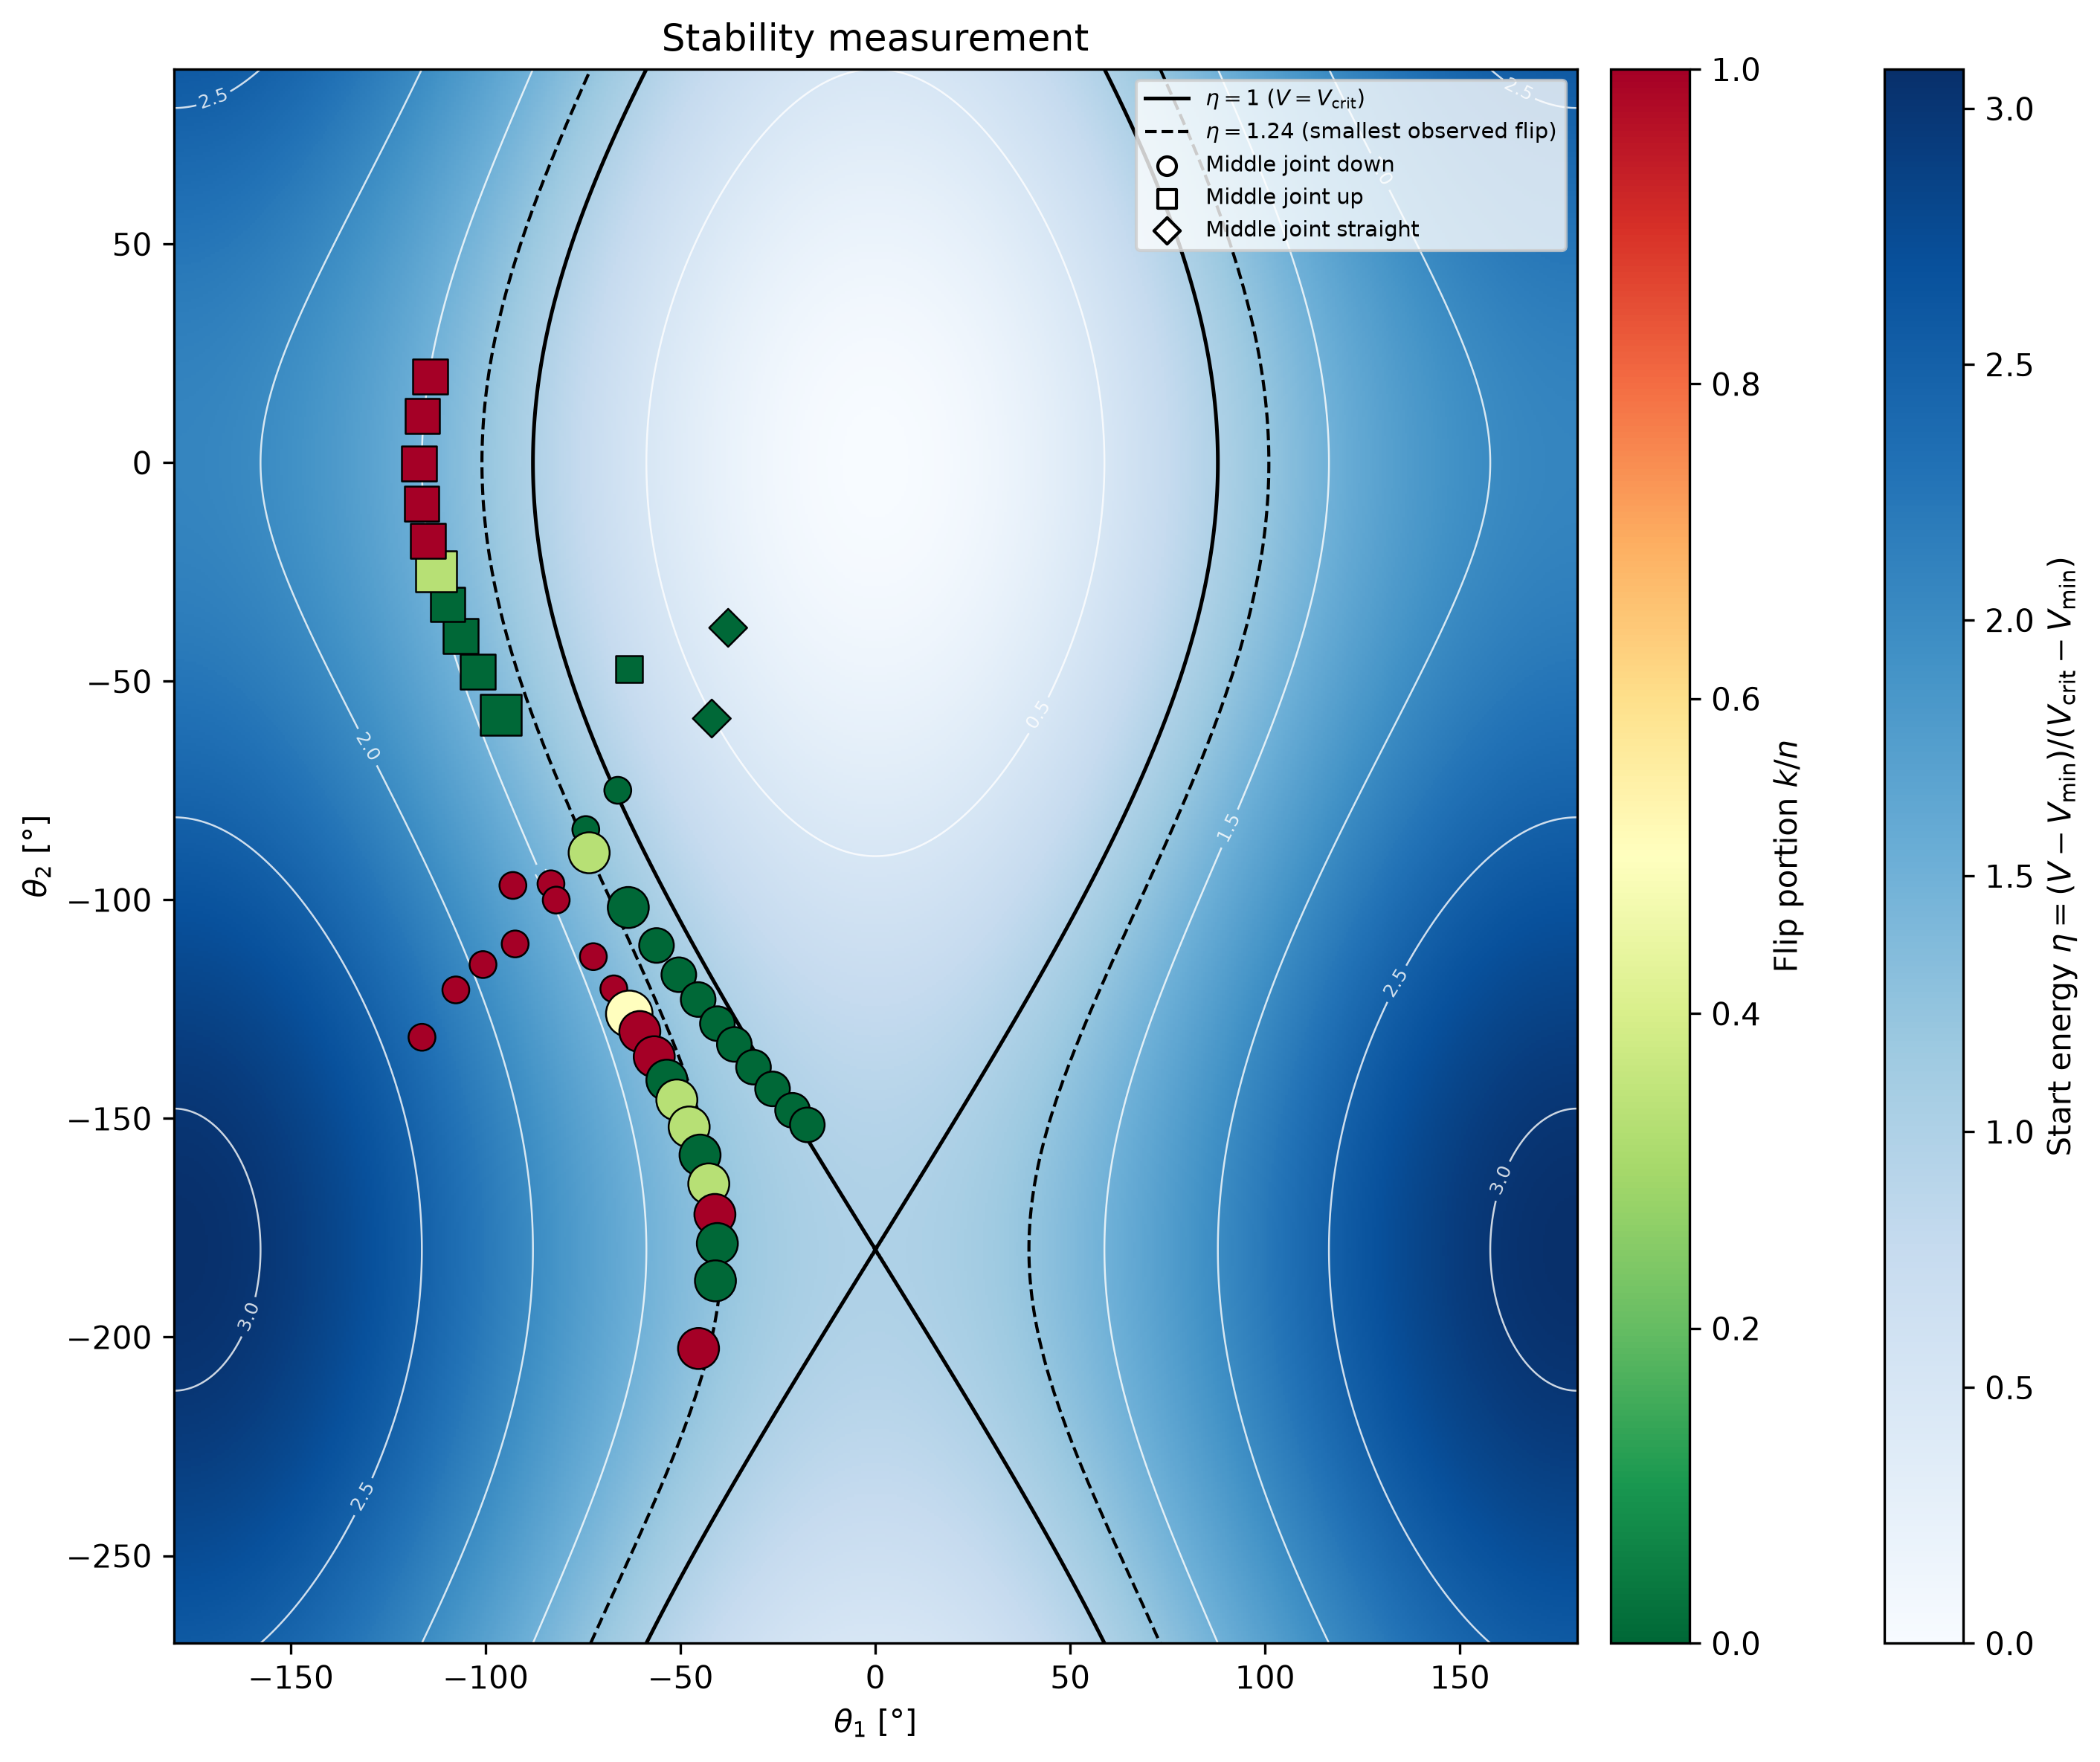

In [11]:
x_lim = np.array([-180, 180])
y_lim = np.array([-270, 90])

fig, ax = plt.subplots(figsize=(10, 8), dpi=300)

# --- Hintergrund: Heatmap der normierten Startenergie eta ---
th1_grid, th2_grid = np.meshgrid(np.linspace(*x_lim, 600),
                                 np.linspace(*y_lim, 600))
eta_grid = eta(np.deg2rad(th1_grid), np.deg2rad(th2_grid))

hm = ax.pcolormesh(th1_grid, th2_grid, eta_grid, cmap="Blues",
                   vmin=0, vmax=eta_grid.max(), shading="auto", zorder=0)
fig.colorbar(hm, ax=ax, pad=0.01, label=r"Start energy $\eta = (V - V_\mathrm{min})/(V_\mathrm{crit} - V_\mathrm{min})$")

# dünne Höhenlinien zur Orientierung, mit Beschriftung
iso = ax.contour(th1_grid, th2_grid, eta_grid, levels=[0.5, 1.5, 2.0, 2.5, 3.0],
                 colors="white", linewidths=0.6, alpha=0.8)
ax.clabel(iso, fmt="%.1f", fontsize=6, zorder=1)

# Theorie-Schwelle (eta = 1) und kleinster beobachteter Flip
ax.contour(th1_grid, th2_grid, eta_grid, levels=[1], colors="black", linewidths=1.2)
ax.contour(th1_grid, th2_grid, eta_grid, levels=[eta_min_flip],
           colors="black", linestyles="--", linewidths=1)
ax.plot([], [], color="black", lw=1.2, label=r"$\eta = 1$ ($V = V_\mathrm{crit}$)")
ax.plot([], [], color="black", ls="--", lw=1,
        label=rf"$\eta = {eta_min_flip:.2f}$ (smallest observed flip)")

# --- Messpunkte, je Gelenkstellung ein Marker ---
markers = {"down": "o", "up": "s", "straight": "D"}
for j, mk in markers.items():
    sub = groups[groups["joint"] == j]
    sc = ax.scatter(sub["theta_1"], sub["theta_2"],
                    c=sub["p"], cmap="RdYlGn_r", vmin=0, vmax=1,
                    s=25 + 50 * sub["n"],
                    marker=mk, edgecolors="black", linewidths=0.6, zorder=3)
    ax.scatter([], [], marker=mk, facecolors="white", edgecolors="black", label=f"Middle joint {j}")

fig.colorbar(sc, ax=ax, pad=0.02, label="Flip portion $k/n$")

ax.set_xlabel(r"$\theta_1$ [°]")
ax.set_ylabel(r"$\theta_2$ [°]")
ax.set_xlim(*x_lim)
ax.set_ylim(*y_lim)
ax.set_title("Stability measurement")
ax.legend(fontsize=7, loc="upper right")
fig.tight_layout()
fig.savefig("final_plots/flip_heatmap.png")
plt.show()

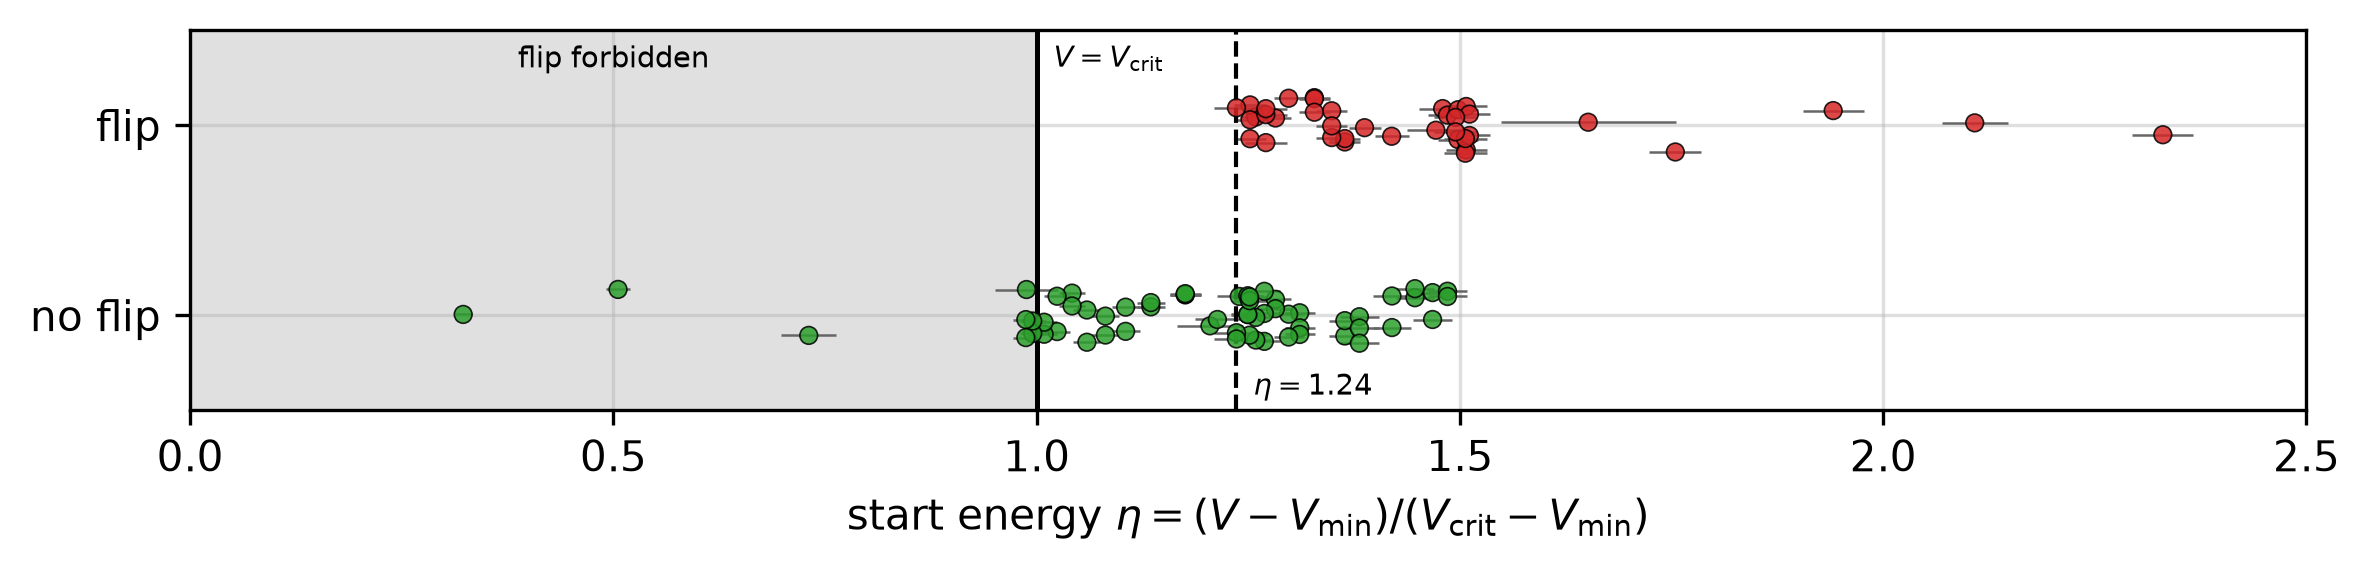

In [13]:
fig, ax = plt.subplots(figsize=(8, 2), dpi=300)
rng_y = np.random.default_rng(1)

y = data["flip"] + 0.15 * rng_y.uniform(-1, 1, len(data))   # leicht verstreut, damit gleiche Punkte sichtbar bleiben
color = np.where(data["flip"] == 1, "tab:red", "tab:green")
ax.errorbar(data["eta"], y, xerr=data["s_eta"], fmt="none", ecolor="0.4", lw=0.6, zorder=2)
ax.scatter(data["eta"], y, c=color, s=18, edgecolors="black", linewidths=0.4, alpha=0.85, zorder=3)

ax.axvspan(0, 1, color="0.88", zorder=0)
ax.axvline(1, color="black", lw=1.2)
ax.axvline(eta_min_flip, color="black", ls="--", lw=1)
ax.text(1.02, 1.42, r"$V = V_\mathrm{crit}$", fontsize=7, va="top")
ax.text(eta_min_flip + 0.02, -0.42, rf"$\eta = {eta_min_flip:.2f}$", fontsize=7)
ax.text(0.5, 1.42, "flip forbidden", fontsize=7, ha="center", va="top")

ax.set_yticks([0, 1], ["no flip", "flip"])
ax.set_ylim(-0.5, 1.5)
ax.set_xlim(0, 2.5)
ax.set_xlabel(r"start energy $\eta = (V - V_\mathrm{min})/(V_\mathrm{crit} - V_\mathrm{min})$")
ax.grid(alpha=0.4)
fig.tight_layout()
fig.savefig("final_plots/flip_vs_eta.png")
plt.show()

## Simulation (Rein KI generiert mit Claude; zum testen)

### Modell und Funktionen

In [9]:
from matplotlib.colors import LogNorm
import copy

# --- Modell: Massen, Schwerpunkte und Trägheitsmomente (m_2, c_2, I_1, I_2, A, B) aus Zelle oben ---
a = I_1 + m_2 * L_1**2
b = I_2
c = m_2 * L_1 * c_2

def rhs(t1, t2, w1, w2, gamma):
    """Bewegungsgleichungen (Lagrange), gamma = viskose Gelenkreibung [N m s]."""
    d = t1 - t2
    cd, sd = np.cos(d), np.sin(d)
    r1 = -c * sd * w2**2 - A * np.sin(t1) - gamma * w1
    r2 =  c * sd * w1**2 - B * np.sin(t2) - gamma * (w2 - w1)
    det = a * b - (c * cd)**2
    return w1, w2, (b * r1 - c * cd * r2) / det, (a * r2 - c * cd * r1) / det


def energy(t1, t2, w1, w2):
    """Gesamtenergie (kinetisch + potentiell) des Doppelpendels."""
    return (0.5 * a * w1**2 + 0.5 * b * w2**2 + c * w1 * w2 * np.cos(t1 - t2)
            - A * np.cos(t1) - B * np.cos(t2))


def flip_time(t1, t2, gamma=0.0, T=20.0, dt=2e-3, check_every=25):
    """Zeit bis zum ersten Überschlag des Unterarms (|theta_2| erreicht pi), Start aus der Ruhe.
    t1, t2: Startwinkel in rad (t2 in (-pi, pi]); gamma: Skalar oder Array gleicher Form.
    Kein Flip bis T -> inf.

    Effizienz: Es wird nur weitergerechnet, solange ein Flip noch möglich ist.
    - geflippte Trajektorien fallen sofort weg
    - Trajektorien mit E < V_crit fallen weg: Reibung kann E nur verkleinern,
      und ein Flip braucht mindestens V_crit -> exakt, kein Genauigkeitsverlust."""
    shape = np.shape(t1)
    t1 = np.array(t1, dtype=float).ravel()
    t2 = np.array(t2, dtype=float).ravel()
    gam = np.broadcast_to(np.asarray(gamma, dtype=float), shape).ravel().copy()
    w1 = np.zeros_like(t1); w2 = np.zeros_like(t1)
    tf = np.full(t1.size, np.inf)
    idx = np.arange(t1.size)                       # Originalindex der noch aktiven Trajektorien

    V_crit_ = -A + B
    tol = 1e-6 * abs(V_crit_)                      # Sicherheitsmarge für numerische Rundung
    alive = energy(t1, t2, w1, w2) >= V_crit_ - tol    # Start unter der Schwelle -> nie Flip
    t1, t2, w1, w2, gam, idx = t1[alive], t2[alive], w1[alive], w2[alive], gam[alive], idx[alive]

    for step in range(1, int(T / dt) + 1):
        k1 = rhs(t1, t2, w1, w2, gam)
        k2 = rhs(t1 + dt/2*k1[0], t2 + dt/2*k1[1], w1 + dt/2*k1[2], w2 + dt/2*k1[3], gam)
        k3 = rhs(t1 + dt/2*k2[0], t2 + dt/2*k2[1], w1 + dt/2*k2[2], w2 + dt/2*k2[3], gam)
        k4 = rhs(t1 + dt*k3[0],   t2 + dt*k3[1],   w1 + dt*k3[2],   w2 + dt*k3[3],   gam)
        t1 = t1 + dt/6 * (k1[0] + 2*k2[0] + 2*k3[0] + k4[0])
        t2 = t2 + dt/6 * (k1[1] + 2*k2[1] + 2*k3[1] + k4[1])
        w1 = w1 + dt/6 * (k1[2] + 2*k2[2] + 2*k3[2] + k4[2])
        w2 = w2 + dt/6 * (k1[3] + 2*k2[3] + 2*k3[3] + k4[3])

        flipped = np.abs(t2) >= np.pi
        tf[idx[flipped]] = step * dt

        keep = ~flipped
        if step % check_every == 0:                # Energie-Test nicht jeden Schritt (spart Zeit)
            keep &= energy(t1, t2, w1, w2) >= V_crit_ - tol
        if not keep.all():
            t1, t2, w1, w2, gam, idx = t1[keep], t2[keep], w1[keep], w2[keep], gam[keep], idx[keep]
        if idx.size == 0:
            break
    return tf.reshape(shape)

def to_sim(theta_deg):
    """Winkel in Grad -> rad auf (-pi, pi], wie die Simulation sie braucht."""
    return (np.deg2rad(theta_deg) + np.pi) % (2 * np.pi) - np.pi

### Reibung an die Messung anpassen

In [10]:
#gammas = np.array([0, 1e-4, 3e-4, 1e-3, 3e-3])    # N m s
gammas = np.array([0, 2e-4, 3e-4, 4e-4, 5e-4])
#gammas = np.array([3e-4])

rng = np.random.default_rng(1)
J = 40                                             # Simulationen pro Messposition
t1_start = to_sim(groups["theta_1"].values)
t2_start = to_sim(groups["theta_2"].values)
s1 = t1_start[:, None] + np.deg2rad(0.5) * rng.standard_normal((len(groups), J))
s2 = t2_start[:, None] + np.deg2rad(0.5) * rng.standard_normal((len(groups), J))
k, n = groups["k"].values, groups["n"].values

# alle gammas in einem Aufruf: Achsen (gamma, Messposition, Wiederholung)
G = gammas[:, None, None] * np.ones_like(s1)[None]
tf_pts = flip_time(np.broadcast_to(s1, G.shape), np.broadcast_to(s2, G.shape), gamma=G, T=20)

p_sim = np.clip(np.isfinite(tf_pts).mean(axis=2), 0.02, 0.98)   # Form (gamma, Messposition)
logL = np.sum(k * np.log(p_sim) + (n - k) * np.log(1 - p_sim), axis=1)
agree = np.mean((p_sim > 0.5) == (k / n > 0.5), axis=1)
for gm, L_, ag in zip(gammas, logL, agree):
    print(f"gamma = {gm:.0e} N m s:  logL = {L_:7.1f},  Übereinstimmung = {ag:.2f}")

gamma = 0e+00 N m s:  logL =  -168.9,  Übereinstimmung = 0.53
gamma = 2e-04 N m s:  logL =   -37.7,  Übereinstimmung = 0.92
gamma = 3e-04 N m s:  logL =   -70.7,  Übereinstimmung = 0.86
gamma = 4e-04 N m s:  logL =   -82.2,  Übereinstimmung = 0.84
gamma = 5e-04 N m s:  logL =  -103.4,  Übereinstimmung = 0.78


### Flip-Map auf dem Gitter rechnen

In [11]:
N = 320
T_sim = 30.0

th1_axis = np.linspace(-180, 180, N)
th2_axis = np.linspace(-270, 90, N)
TH1, TH2 = np.meshgrid(th1_axis, th2_axis)

# Gitter für jedes gamma kopieren -> Form (gamma, N, N), ein einziger Aufruf
G = gammas[:, None, None] * np.ones((1, N, N))
tf_grids = flip_time(np.broadcast_to(to_sim(TH1), G.shape),
                     np.broadcast_to(to_sim(TH2), G.shape), gamma=G, T=T_sim)

### Plot

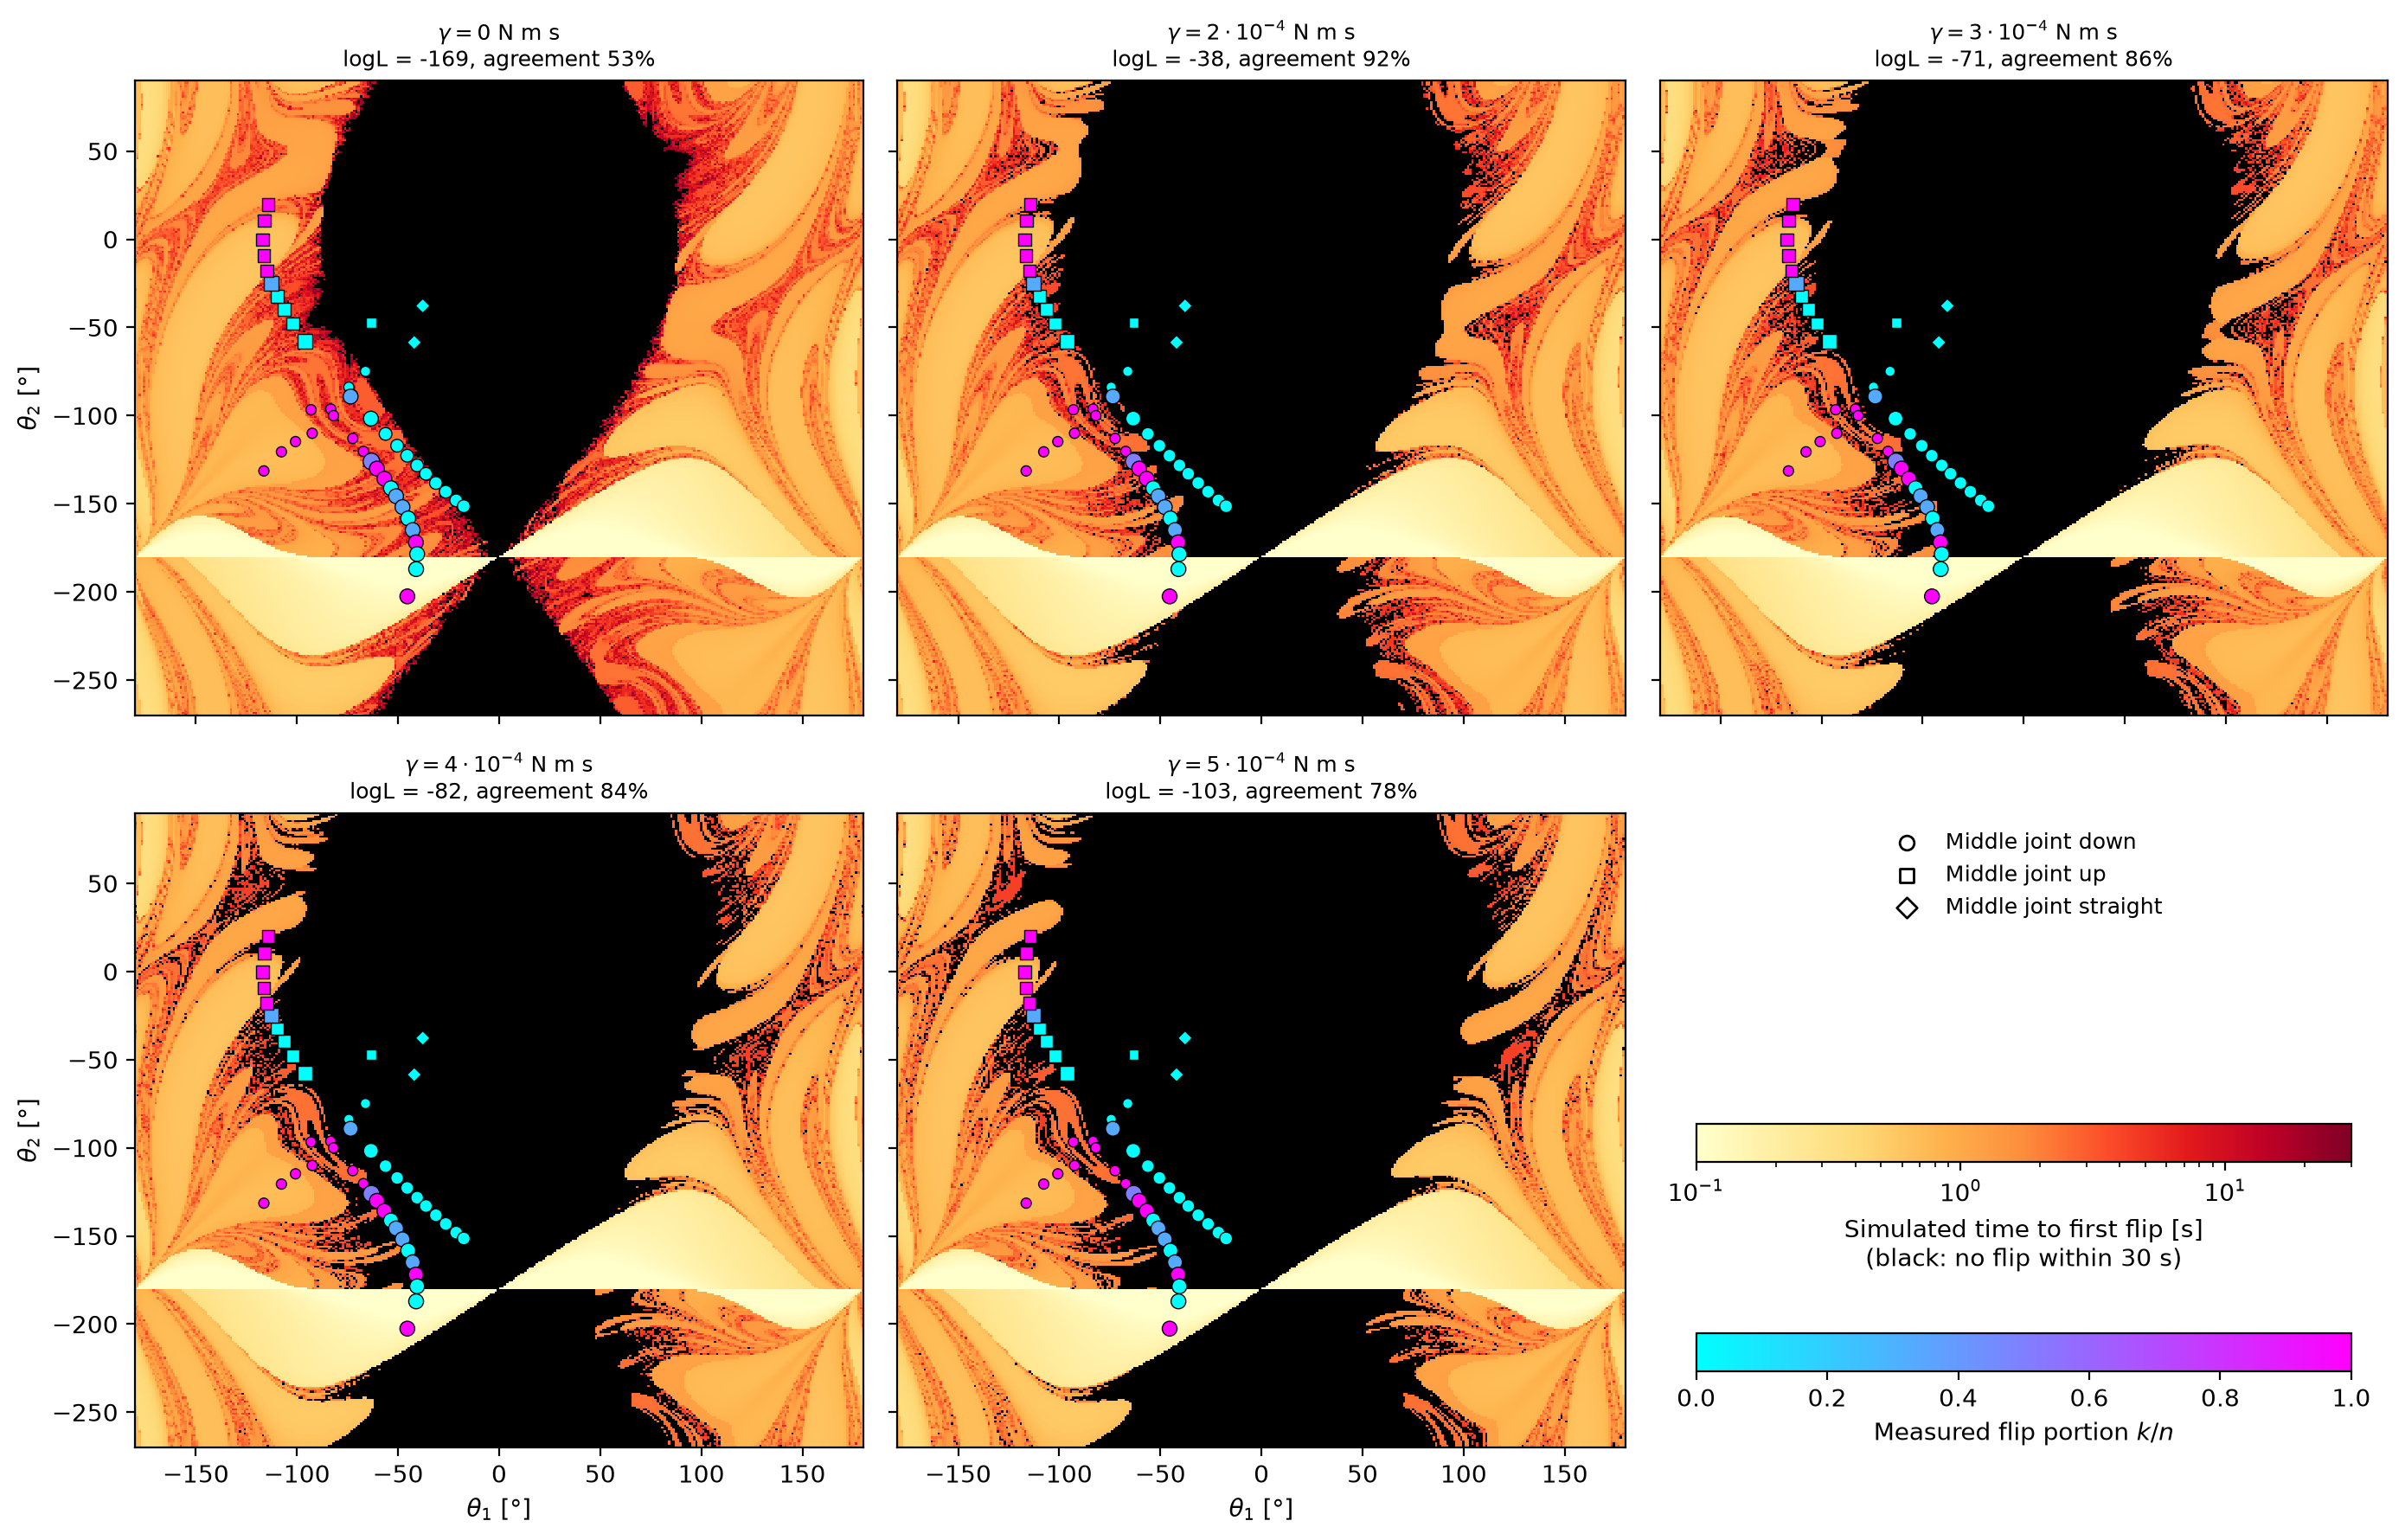

In [12]:
def gamma_label(gm):
    """3e-04 -> 3\\cdot10^{-4} für schöne Titel."""
    if gm == 0:
        return "0"
    mant, exp = f"{gm:.0e}".split("e")
    return rf"{mant}\cdot10^{{{int(exp)}}}"


cmap_sim = copy.copy(plt.get_cmap("YlOrRd"))
cmap_sim.set_bad("black")                          # kein Flip -> schwarz
markers = {"down": "o", "up": "s", "straight": "D"}

fig, axes = plt.subplots(2, 3, figsize=(14, 9), dpi=200, sharex=True, sharey=True)
for ax, gm, tf_g, L_, ag in zip(axes.flat, gammas, tf_grids, logL, agree):
    ax.set_facecolor("black")
    tf_plot = np.ma.masked_invalid(np.where(np.isinf(tf_g), np.nan, tf_g))
    hm = ax.pcolormesh(th1_axis, th2_axis, tf_plot, cmap=cmap_sim,
                       norm=LogNorm(0.1, T_sim), shading="auto")
    for j, mk in markers.items():
        sub = groups[groups["joint"] == j]
        sc = ax.scatter(sub["theta_1"], sub["theta_2"], c=sub["p"], cmap="cool",
                        vmin=0, vmax=1, s=8 + 10 * sub["n"], marker=mk,
                        edgecolors="black", linewidths=0.5, zorder=3)
    ax.set_title(rf"$\gamma = {gamma_label(gm)}$ N m s" + f"\nlogL = {L_:.0f}, agreement {ag:.0%}",
                 fontsize=9)
    ax.set_xlim(-180, 180)
    ax.set_ylim(-270, 90)

for ax in axes[1]:
    ax.set_xlabel(r"$\theta_1$ [°]")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$\theta_2$ [°]")

# 6. Feld: Legende und beide Farbbalken
ax_info = axes.flat[-1]
ax_info.axis("off")
for j, mk in markers.items():
    ax_info.scatter([], [], marker=mk, facecolors="white", edgecolors="black", label=f"Middle joint {j}")
ax_info.legend(loc="upper center", fontsize=9, frameon=False)
cax1 = ax_info.inset_axes([0.05, 0.45, 0.9, 0.06])
cax2 = ax_info.inset_axes([0.05, 0.12, 0.9, 0.06])
fig.colorbar(hm, cax=cax1, orientation="horizontal",
             label=f"Simulated time to first flip [s]\n(black: no flip within {T_sim:g} s)")
fig.colorbar(sc, cax=cax2, orientation="horizontal", label="Measured flip portion $k/n$")

fig.tight_layout()
#fig.savefig("final_plots/flip_simulation_gammas.pdf")
plt.show()

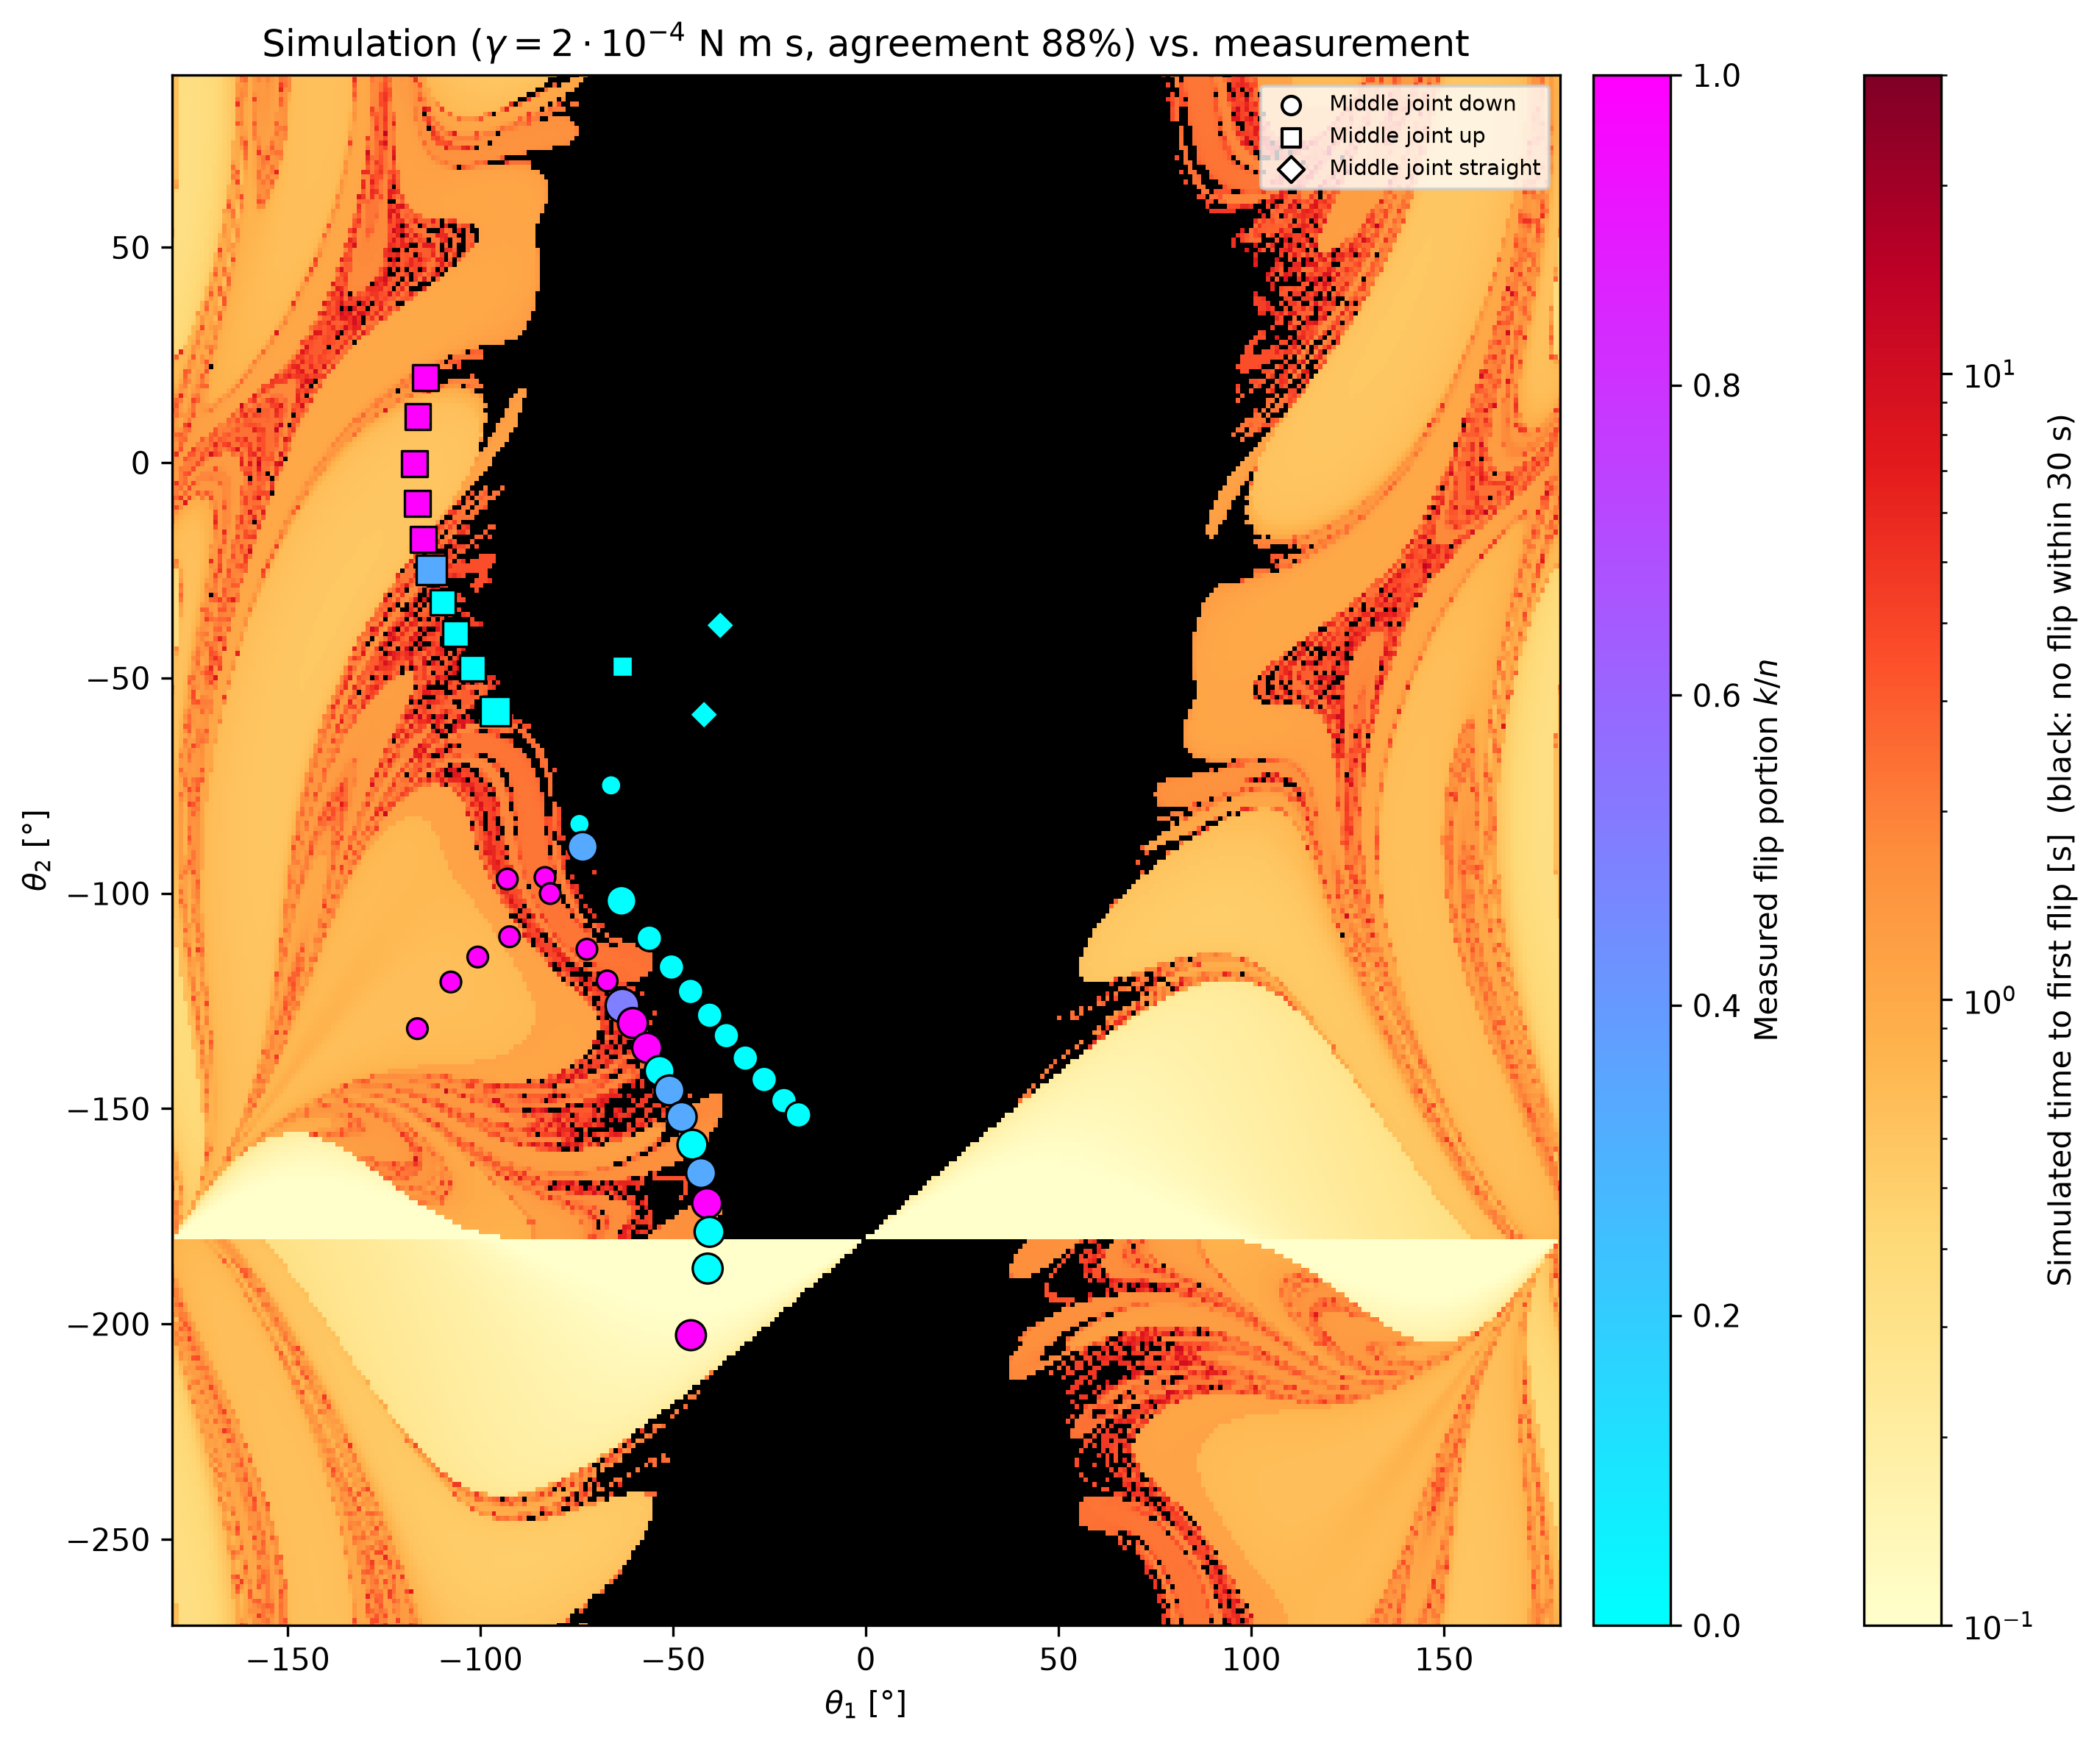

Bestes gamma: 2e-04 N m s  (logL = -54.8)


In [118]:
i_best = np.argmax(logL)                           # Index des gamma mit der grössten Likelihood
gamma_best = gammas[i_best]
tf_best = tf_grids[i_best]

cmap_sim = copy.copy(plt.get_cmap("YlOrRd"))
cmap_sim.set_bad("black")                          # kein Flip -> schwarz
markers = {"down": "o", "up": "s", "straight": "D"}

fig, ax = plt.subplots(figsize=(10, 8), dpi=300)
ax.set_facecolor("black")

tf_plot = np.ma.masked_invalid(np.where(np.isinf(tf_best), np.nan, tf_best))
hm = ax.pcolormesh(th1_axis, th2_axis, tf_plot, cmap=cmap_sim,
                   norm=LogNorm(0.1, T_sim), shading="auto")
fig.colorbar(hm, ax=ax, pad=0.01,
             label=f"Simulated time to first flip [s]  (black: no flip within {T_sim:g} s)")

for j, mk in markers.items():
    sub = groups[groups["joint"] == j]
    sc = ax.scatter(sub["theta_1"], sub["theta_2"], c=sub["p"], cmap="cool",
                    vmin=0, vmax=1, s=20 + 25 * sub["n"], marker=mk,
                    edgecolors="black", linewidths=0.8, zorder=3)
    ax.scatter([], [], marker=mk, facecolors="white", edgecolors="black", label=f"Middle joint {j}")
fig.colorbar(sc, ax=ax, pad=0.02, label="Measured flip portion $k/n$")

ax.set_xlim(-180, 180)
ax.set_ylim(-270, 90)
ax.set_xlabel(r"$\theta_1$ [°]")
ax.set_ylabel(r"$\theta_2$ [°]")
ax.set_title(rf"Simulation ($\gamma = {gamma_label(gamma_best)}$ N m s, "
             rf"agreement {agree[i_best]:.0%}) vs. measurement")
ax.legend(fontsize=7, loc="upper right")
fig.tight_layout()
#fig.savefig("final_plots/flip_simulation_best.pdf")
plt.show()

print(f"Bestes gamma: {gamma_best:.0e} N m s  (logL = {logL[i_best]:.1f})")